In [16]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import io

In [3]:
    


    
df = pd.read_csv('../data/tmp/confmatrix.csv')    
    


ax.set_xlabel('Ground truth')
ax.set_ylabel('Predicted')

io_buf = io.BytesIO()
#fig.savefig(io_buf, format='raw', bbox_inches="tight")
fig.savefig(io_buf, format='raw')
io_buf.seek(0)

img_arr = np.reshape(np.frombuffer(io_buf.getvalue(), dtype=np.uint8),
                newshape=(int(fig.bbox.bounds[3]), int(fig.bbox.bounds[2]), -1))

io_buf.close()
plt.close()

return img_arr

NameError: name 'pp_matrix' is not defined

In [9]:

def ___cm_analysis(y_true, y_pred, labels, filename=None, ymap=None, figsize=(10,10)):
    """
    Generate matrix plot of confusion matrix with pretty annotations.
    The plot image is saved to disk.
    args: 
      y_true:    true label of the data, with shape (nsamples,)
      y_pred:    prediction of the data, with shape (nsamples,)
      labels:    string array, name the order of class labels in the confusion matrix.
                 use `clf.classes_` if using scikit-learn models.
                 with shape (nclass,).
      filename:  filename of figure file to save     
      ymap:      dict: any -> string, length == nclass.
                 if not None, map the labels & ys to more understandable strings.
                 Caution: original y_true, y_pred and labels must align.
      figsize:   the size of the figure plotted.
    """
    if ymap is not None:
        y_pred = [ymap[yi] for yi in y_pred]
        y_true = [ymap[yi] for yi in y_true]
        labels = [ymap[yi] for yi in labels]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_sum = np.sum(cm, axis=1, keepdims=True)
    cm_perc = cm / cm_sum.astype(float) * 100
    annot = np.empty_like(cm).astype(str)
    nrows, ncols = cm.shape
    for i in range(nrows):
        for j in range(ncols):
            c = cm[i, j]
            p = cm_perc[i, j]
            if i == j:
                s = cm_sum[i]
                annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)
            elif c == 0:
                annot[i, j] = ''
            else:
                annot[i, j] = '%.1f%%\n%d' % (p, c)
    cm = pd.DataFrame(cm, index=labels, columns=labels)
    cm.index.name = 'Actual'
    cm.columns.name = 'Predicted'
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(cm, annot=annot, fmt='', ax=ax)
    #plt.savefig(filename)
    plt.show()

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def cm_analysis(y_true, y_pred, labels, filename=None, ymap=None, figsize=(10,10)):
    """
    Generate matrix plot of confusion matrix with pretty annotations.
    The plot image is saved to disk.
    args: 
      y_true:    true label of the data, with shape (nsamples,)
      y_pred:    prediction of the data, with shape (nsamples,)
      labels:    string array, name the order of class labels in the confusion matrix.
                 use `clf.classes_` if using scikit-learn models.
                 with shape (nclass,).
      filename:  filename of figure file to save     
      ymap:      dict: any -> string, length == nclass.
                 if not None, map the labels & ys to more understandable strings.
                 Caution: original y_true, y_pred and labels must align.
      figsize:   the size of the figure plotted.
    """
    if ymap is not None:
        y_pred = [ymap[yi] for yi in y_pred]
        y_true = [ymap[yi] for yi in y_true]
        labels = [ymap[yi] for yi in labels]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_sum = np.sum(cm, axis=1, keepdims=True)
    cm_perc = cm / cm_sum.astype(float) * 100
    annot = np.empty_like(cm).astype(str)
    nrows, ncols = cm.shape
    for i in range(nrows):
        for j in range(ncols):
            c = cm[i, j]
            p = cm_perc[i, j]
            if i == j:
                s = cm_sum[i]
                annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)
            elif c == 0:
                annot[i, j] = ''
            else:
                annot[i, j] = '%.1f%%\n%d' % (p, c)
    cm = pd.DataFrame(cm, index=labels, columns=labels)
    cm.index.name = 'Actual'
    cm.columns.name = 'Predicted'
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(cm, annot=annot, fmt='', ax=ax)
    #plt.show()
    
    io_buf = io.BytesIO()
    #fig.savefig(io_buf, format='raw', bbox_inches="tight")
    fig.savefig(io_buf, format='raw')
    io_buf.seek(0)

    img_arr = np.reshape(np.frombuffer(io_buf.getvalue(), dtype=np.uint8),
                    newshape=(int(fig.bbox.bounds[3]), int(fig.bbox.bounds[2]), -1))

    io_buf.close()
    plt.close()
    return img_arr

In [39]:
LABEL_MAPPING = {
    'pasture' : 0, 
    'forest plantation' : 1,
    'soy' : 2,
    'coffee' : 3,
    'palm oil': 4,
    'mining': 5,
    'urban': 6,
    'cocoa': 7,
    'rubber': 8
}

LABEL_MAPPING_inv = {value:key for key, value in LABEL_MAPPING.items()}

In [61]:
y_true = np.array([1,1,1,1,0,0,0,0,5,5,8,8,])
y_pred = np.array([0,1,2,3,4,5,6,7,8,8,8,8])
labels = np.arange(9)
ymap=LABEL_MAPPING_inv

In [44]:
arr = cm_analysis(y_true, y_pred, labels=np.arange(9),  ymap=LABEL_MAPPING_inv)

/tmp/ipykernel_23357/2294846522.py:29: RuntimeWarning: invalid value encountered in divide
  cm_perc = cm / cm_sum.astype(float) * 100
/tmp/ipykernel_23357/2294846522.py:38: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)


In [25]:
arr.shape

(1000, 1000, 4)

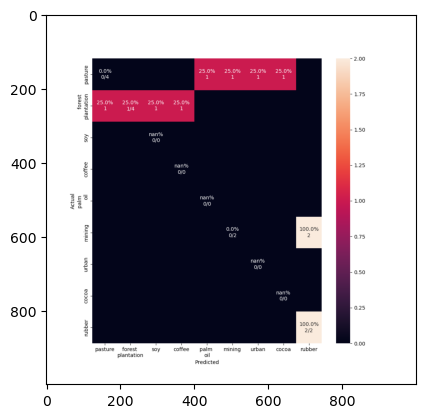

In [26]:
plt.imshow(arr)

In [31]:
ymap

{0: 'pasture',
 1: 'forest \nplantation',
 2: 'soy',
 3: 'coffee',
 4: 'palm \noil',
 5: 'mining',
 6: 'urban',
 7: 'cocoa',
 8: 'rubber'}

/tmp/ipykernel_23357/166919326.py:22: RuntimeWarning: invalid value encountered in divide
  cm_perc = cm / cm_sum.astype(float) * 100
/tmp/ipykernel_23357/166919326.py:31: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)


ValueError: cannot reshape array of size 3011760 into shape (1000,1000,newaxis)

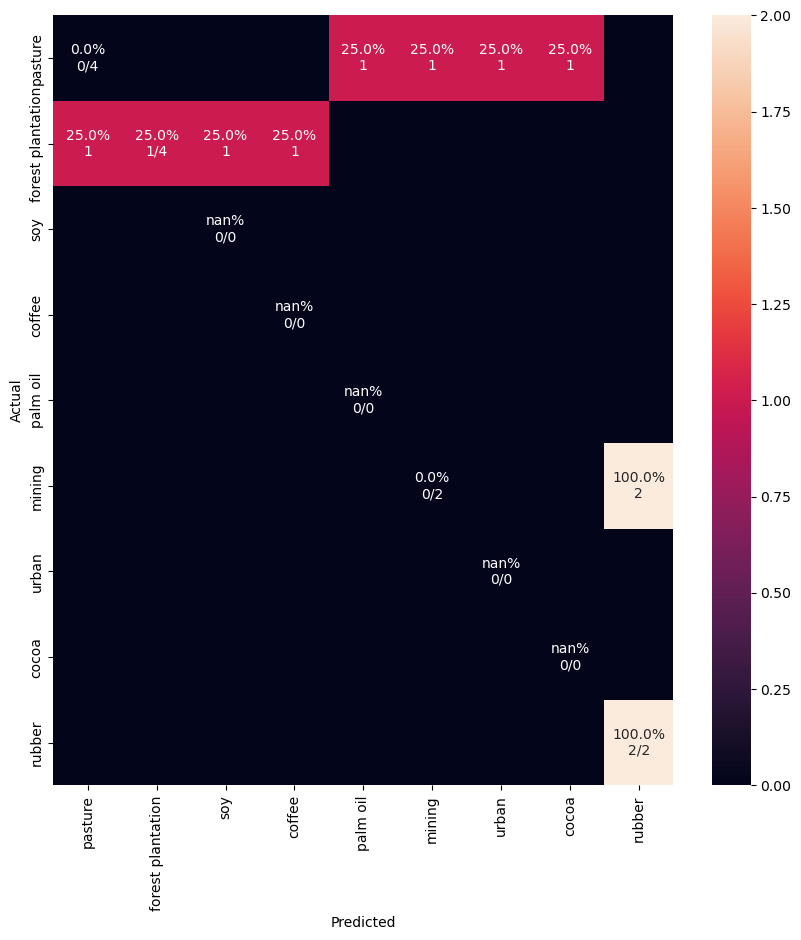

In [62]:
"""
Generate matrix plot of confusion matrix with pretty annotations.
The plot image is saved to disk.
args: 
  y_true:    true label of the data, with shape (nsamples,)
  y_pred:    prediction of the data, with shape (nsamples,)
  labels:    string array, name the order of class labels in the confusion matrix.
             use `clf.classes_` if using scikit-learn models.
             with shape (nclass,).
  filename:  filename of figure file to save     
  ymap:      dict: any -> string, length == nclass.
             if not None, map the labels & ys to more understandable strings.
             Caution: original y_true, y_pred and labels must align.
  figsize:   the size of the figure plotted.
"""
if ymap is not None:
    y_pred = [ymap[yi] for yi in y_pred]
    y_true = [ymap[yi] for yi in y_true]
    labels = [ymap[yi] for yi in labels]
cm = confusion_matrix(y_true, y_pred, labels=labels)
cm_sum = np.sum(cm, axis=1, keepdims=True)
cm_perc = cm / cm_sum.astype(float) * 100
annot = np.empty_like(cm).astype(str)
nrows, ncols = cm.shape
for i in range(nrows):
    for j in range(ncols):
        c = cm[i, j]
        p = cm_perc[i, j]
        if i == j:
            s = cm_sum[i]
            annot[i, j] = '%.1f%%\n%d/%d' % (p, c, s)
        elif c == 0:
            annot[i, j] = ''
        else:
            annot[i, j] = '%.1f%%\n%d' % (p, c)
cm = pd.DataFrame(cm, index=labels, columns=labels)
cm.index.name = 'Actual'
cm.columns.name = 'Predicted'
fig, ax = plt.subplots(figsize=(10,10))
sns.heatmap(cm, annot=annot, fmt='', ax=ax)
#plt.show()

io_buf = io.BytesIO()
fig.savefig(io_buf, format='raw', bbox_inches="tight")
#fig.savefig(io_buf, format='raw')
io_buf.seek(0)

img_arr = np.reshape(np.frombuffer(io_buf.getvalue(), dtype=np.uint8),
                newshape=(int(fig.bbox.bounds[3]), int(fig.bbox.bounds[2]), -1))

#io_buf.close()
#plt.close()


In [57]:
np.frombuffer(io_buf.getvalue()).shape

(500000,)

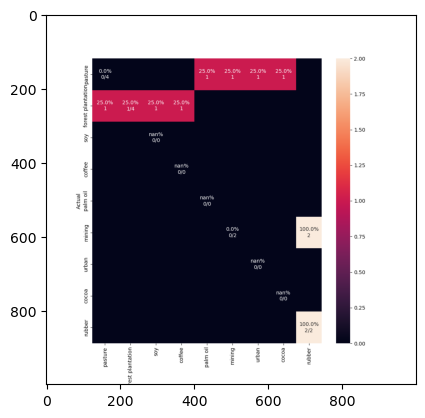

In [60]:
plt.imshow(img_arr)